In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
%cd /content/drive/MyDrive/watertwin
!ls -R | head -40

/content/drive/MyDrive/watertwin
.:
hh-01
hh-01.zip

./hh-01:
hh-01
__MACOSX

./hh-01/hh-01:
info.json
info.txt
smartmeter.csv

./hh-01/__MACOSX:
hh-01

./hh-01/__MACOSX/hh-01:


In [7]:
import pandas as pd

df = pd.read_csv("hh-01/hh-01/smartmeter.csv")

print("Shape:", df.shape)
print(df.head(10))
print(df.dtypes)

Shape: (1388374, 3)
                        time    unixtime  total_m3
0  2020-12-15 07:51:57+00:00  1608018717     29.67
1  2020-12-15 07:52:09+00:00  1608018729     29.67
2  2020-12-15 07:52:20+00:00  1608018740     29.67
3  2020-12-15 07:52:32+00:00  1608018752     29.67
4  2020-12-15 07:52:44+00:00  1608018764     29.67
5  2020-12-15 07:52:56+00:00  1608018776     29.67
6  2020-12-15 07:53:08+00:00  1608018788     29.67
7  2020-12-15 07:53:20+00:00  1608018800     29.67
8  2020-12-15 07:53:32+00:00  1608018812     29.67
9  2020-12-15 07:53:43+00:00  1608018823     29.67
time         object
unixtime      int64
total_m3    float64
dtype: object


In [8]:
df["time"] = pd.to_datetime(df["time"])

print("Start:", df["time"].min())
print("End:", df["time"].max())
print("Missing values:")
print(df.isna().sum())
print("Min reading:", df["total_m3"].min())
print("Max reading:", df["total_m3"].max())
print("Reading ghati kitni baar:", (df["total_m3"].diff() < 0).sum())

Start: 2020-12-15 07:51:57+00:00
End: 2021-06-24 11:46:20+00:00
Missing values:
time        0
unixtime    0
total_m3    0
dtype: int64
Min reading: 29.67
Max reading: 74.12100000000001
Reading ghati kitni baar: 2


In [9]:
# Rows where the reading dropped (compared to previous row)
drop_idx = df.index[df["total_m3"].diff() < 0]

for i in drop_idx:
    print(df.loc[i - 2 : i + 2, ["time", "total_m3"]])
    print("-" * 40)

# Largest time gaps between consecutive readings
gaps = df["time"].diff().sort_values(ascending=False).head(5)
print("Largest gaps:")
print(gaps)

                             time  total_m3
1249776 2021-06-05 11:28:34+00:00    70.048
1249777 2021-06-05 11:28:38+00:00    70.067
1249778 2021-06-05 11:28:45+00:00    70.048
1249779 2021-06-05 11:28:50+00:00    70.067
1249780 2021-06-05 11:28:57+00:00    70.048
----------------------------------------
                             time  total_m3
1249778 2021-06-05 11:28:45+00:00    70.048
1249779 2021-06-05 11:28:50+00:00    70.067
1249780 2021-06-05 11:28:57+00:00    70.048
1249781 2021-06-05 11:29:09+00:00    70.048
1249782 2021-06-05 11:29:21+00:00    70.048
----------------------------------------
Largest gaps:
4454    0 days 01:35:19
7949    0 days 01:31:10
8013    0 days 01:10:57
67312   0 days 00:42:10
6410    0 days 00:36:24
Name: time, dtype: timedelta64[ns]


In [10]:
# Make the cumulative reading non-decreasing (removes the small flicker)
s = df.set_index("time")["total_m3"].cummax()

# Last reading of every hour; fill empty hours by interpolation
hourly = s.resample("1h").last().interpolate()

# Consumption per hour = difference between consecutive hours, in litres
cons = hourly.diff().mul(1000).dropna()

hourly_df = cons.reset_index()
hourly_df.columns = ["timestamp", "consumption_litres"]

print("Rows:", len(hourly_df))
print(hourly_df.head(10))
print(hourly_df["consumption_litres"].describe())
print("Zero-consumption hours:", (hourly_df["consumption_litres"] == 0).sum())

Rows: 4588
                  timestamp  consumption_litres
0 2020-12-15 08:00:00+00:00                 0.0
1 2020-12-15 09:00:00+00:00                 0.0
2 2020-12-15 10:00:00+00:00                 0.0
3 2020-12-15 11:00:00+00:00                 0.0
4 2020-12-15 12:00:00+00:00                 0.0
5 2020-12-15 13:00:00+00:00                 0.0
6 2020-12-15 14:00:00+00:00                 0.0
7 2020-12-15 15:00:00+00:00                 0.0
8 2020-12-15 16:00:00+00:00                 0.0
9 2020-12-15 17:00:00+00:00               145.0
count    4588.000000
mean        9.688099
std        23.388197
min         0.000000
25%         0.000000
50%         0.000000
75%         9.000000
max       285.000000
Name: consumption_litres, dtype: float64
Zero-consumption hours: 2723


In [11]:
import os

# Convert UTC to local German time, then drop the timezone label
hourly_df["timestamp"] = (
    hourly_df["timestamp"].dt.tz_convert("Europe/Berlin").dt.tz_localize(None)
)
hourly_df["block"] = "hh-01"
hourly_df = hourly_df[["timestamp", "block", "consumption_litres"]]

os.makedirs("data", exist_ok=True)
hourly_df.to_csv("data/water_hourly.csv", index=False)

print("Saved:", hourly_df.shape)
print(hourly_df.head(3))

# Average consumption by hour of day
print(hourly_df.groupby(hourly_df["timestamp"].dt.hour)["consumption_litres"].mean().round(1))

Saved: (4588, 3)
            timestamp  block  consumption_litres
0 2020-12-15 09:00:00  hh-01                 0.0
1 2020-12-15 10:00:00  hh-01                 0.0
2 2020-12-15 11:00:00  hh-01                 0.0
timestamp
0      1.5
1      1.0
2      0.5
3      0.8
4      0.4
5      0.7
6     12.2
7     21.2
8     12.6
9     11.0
10    12.3
11     8.4
12    10.3
13     8.7
14     5.7
15     6.3
16     8.6
17    23.0
18    31.9
19    26.3
20    11.0
21     7.7
22     7.2
23     3.2
Name: consumption_litres, dtype: float64


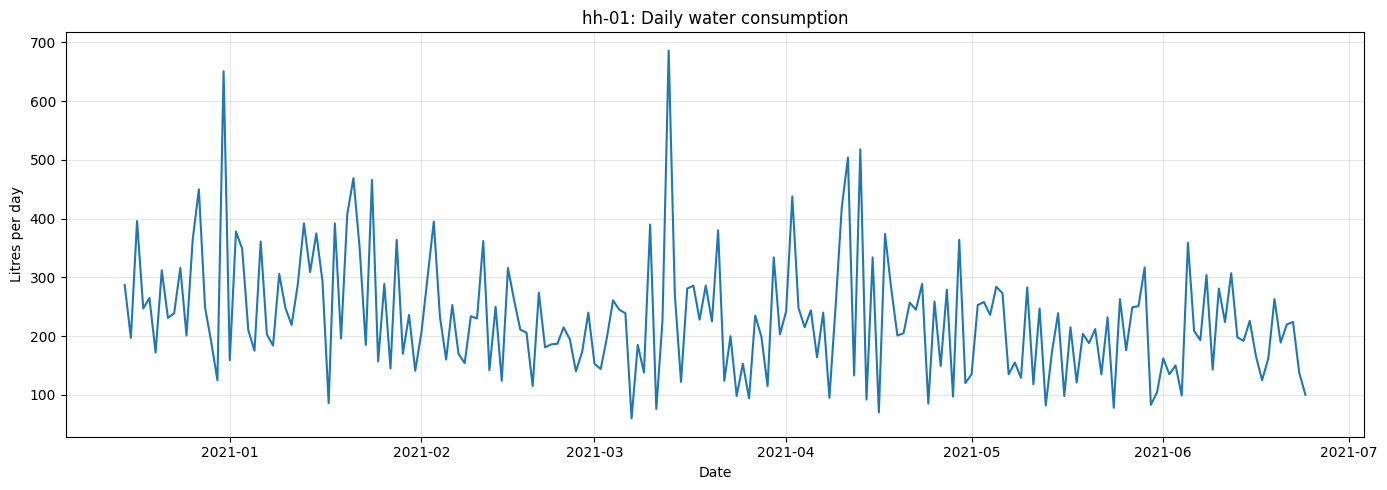

count    192.0
mean     231.5
std      102.7
min       60.0
25%      158.5
50%      222.0
75%      281.0
max      686.0
Name: consumption_litres, dtype: float64
Days with zero use: 0


In [12]:
import matplotlib.pyplot as plt

daily = hourly_df.set_index("timestamp")["consumption_litres"].resample("1D").sum()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values)
plt.title("hh-01: Daily water consumption")
plt.xlabel("Date")
plt.ylabel("Litres per day")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(daily.describe().round(1))
print("Days with zero use:", (daily == 0).sum())

In [13]:
df_ts = hourly_df.copy()
df_ts = df_ts.set_index("timestamp").sort_index()

split_point = int(len(df_ts) * 0.8)
train = df_ts.iloc[:split_point]
test = df_ts.iloc[split_point:]

print("Train rows:", len(train))
print("Train period:", train.index.min(), "to", train.index.max())
print("Test rows:", len(test))
print("Test period:", test.index.min(), "to", test.index.max())
print("Train mean:", round(train["consumption_litres"].mean(), 2))
print("Test mean:", round(test["consumption_litres"].mean(), 2))

Train rows: 3670
Train period: 2020-12-15 09:00:00 to 2021-05-17 07:00:00
Test rows: 918
Test period: 2021-05-17 08:00:00 to 2021-06-24 13:00:00
Train mean: 10.05
Test mean: 8.25


In [14]:
feat = df_ts[["consumption_litres"]].copy()

# Time-based features
feat["hour"] = feat.index.hour
feat["dayofweek"] = feat.index.dayofweek
feat["is_weekend"] = (feat["dayofweek"] >= 5).astype(int)

# Lag features (past consumption)
feat["lag_1"] = feat["consumption_litres"].shift(1)
feat["lag_24"] = feat["consumption_litres"].shift(24)
feat["lag_168"] = feat["consumption_litres"].shift(168)

# Rolling average of the previous 24 hours (shift(1) avoids using the current value)
feat["roll_24"] = feat["consumption_litres"].shift(1).rolling(24).mean()

# Drop the first rows that have no lag values
feat = feat.dropna()

split_point = int(len(feat) * 0.8)
train = feat.iloc[:split_point]
test = feat.iloc[split_point:]

print("Feature columns:", list(feat.columns))
print("Train rows:", len(train), "| Test rows:", len(test))
print("Test period:", test.index.min(), "to", test.index.max())
print(feat.head(3))

Feature columns: ['consumption_litres', 'hour', 'dayofweek', 'is_weekend', 'lag_1', 'lag_24', 'lag_168', 'roll_24']
Train rows: 3536 | Test rows: 884
Test period: 2021-05-18 18:00:00 to 2021-06-24 13:00:00
                     consumption_litres  hour  dayofweek  is_weekend  lag_1  \
timestamp                                                                     
2020-12-22 09:00:00                 0.0     9          1           0    0.0   
2020-12-22 10:00:00                 0.0    10          1           0    0.0   
2020-12-22 11:00:00                 0.0    11          1           0    0.0   

                     lag_24  lag_168    roll_24  
timestamp                                        
2020-12-22 09:00:00     0.0      0.0  13.166667  
2020-12-22 10:00:00     0.0      0.0  13.166667  
2020-12-22 11:00:00     0.0      0.0  13.166667  


In [15]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = test["consumption_litres"]
y_base = test["lag_24"]

mae = mean_absolute_error(y_true, y_base)
rmse = np.sqrt(mean_squared_error(y_true, y_base))

# MAPE only on hours where actual consumption is not zero
mask = y_true > 0
mape = (np.abs(y_true[mask] - y_base[mask]) / y_true[mask]).mean() * 100

print("Baseline (lag_24) results")
print("MAE :", round(mae, 2), "litres/hour")
print("RMSE:", round(rmse, 2), "litres/hour")
print("MAPE:", round(mape, 1), "% (non-zero hours only:", mask.sum(), "of", len(y_true), ")")

Baseline (lag_24) results
MAE : 12.29 litres/hour
RMSE: 26.43 litres/hour
MAPE: 163.9 % (non-zero hours only: 306 of 884 )


In [16]:
from sklearn.ensemble import RandomForestRegressor

features = ["hour", "dayofweek", "is_weekend", "lag_1", "lag_24", "lag_168", "roll_24"]

X_train, y_train = train[features], train["consumption_litres"]
X_test, y_test = test[features], test["consumption_litres"]

rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, rf_pred)
rmse_rf = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest results")
print("MAE :", round(mae_rf, 2), "litres/hour")
print("RMSE:", round(rmse_rf, 2), "litres/hour")
print("Baseline MAE was 12.29, RMSE was 26.43")

# Which features mattered most
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print(imp.round(3))

Random Forest results
MAE : 9.78 litres/hour
RMSE: 18.28 litres/hour
Baseline MAE was 12.29, RMSE was 26.43
hour          0.238
roll_24       0.237
lag_1         0.165
lag_24        0.144
lag_168       0.135
dayofweek     0.073
is_weekend    0.009
dtype: float64


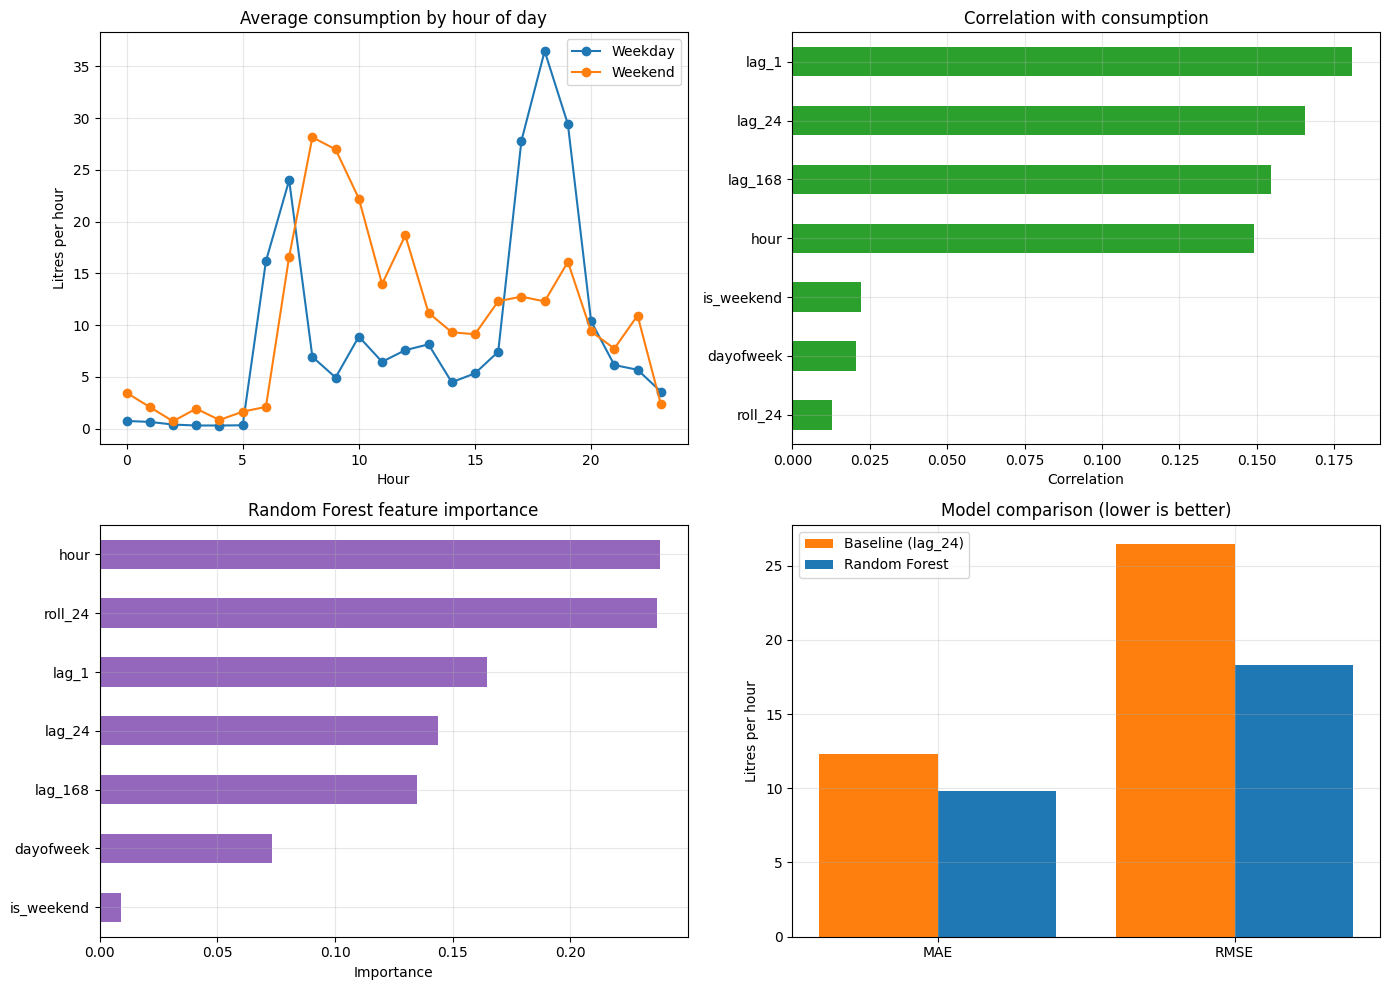

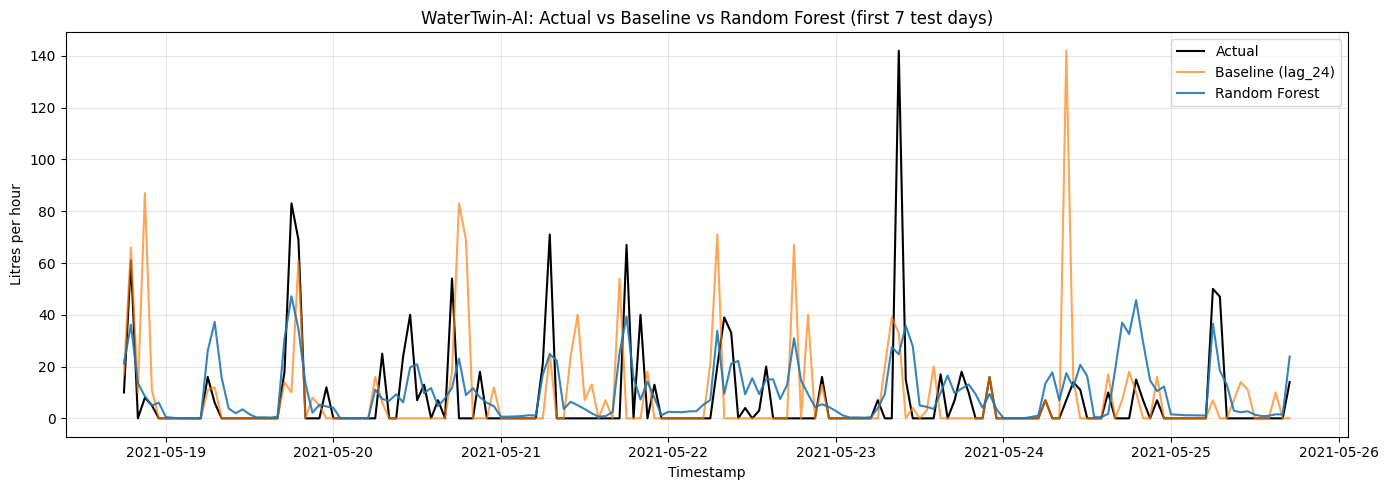

Baseline -> MAE: 12.29 | RMSE: 26.43
Random Forest -> MAE: 9.78 | RMSE: 18.28
hour          0.238
roll_24       0.237
lag_1         0.165
lag_24        0.144
lag_168       0.135
dayofweek     0.073
is_weekend    0.009
dtype: float64


In [17]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1) Average consumption by hour: weekday vs weekend
hr = feat.groupby(["hour", "is_weekend"])["consumption_litres"].mean().unstack()
hr.columns = ["Weekday", "Weekend"]
hr.plot(ax=ax[0, 0], marker="o")
ax[0, 0].set_title("Average consumption by hour of day")
ax[0, 0].set_xlabel("Hour")
ax[0, 0].set_ylabel("Litres per hour")
ax[0, 0].grid(True, alpha=0.3)

# 2) Correlation of each feature with the target (train data only)
corr = train[features + ["consumption_litres"]].corr()["consumption_litres"].drop("consumption_litres")
corr.sort_values().plot(kind="barh", ax=ax[0, 1], color="#2ca02c")
ax[0, 1].set_title("Correlation with consumption")
ax[0, 1].set_xlabel("Correlation")
ax[0, 1].grid(True, alpha=0.3)

# 3) Random Forest feature importance
imp.sort_values().plot(kind="barh", ax=ax[1, 0], color="#9467bd")
ax[1, 0].set_title("Random Forest feature importance")
ax[1, 0].set_xlabel("Importance")
ax[1, 0].grid(True, alpha=0.3)

# 4) Model comparison: MAE and RMSE
labels = ["MAE", "RMSE"]
base_vals = [mae, rmse]
rf_vals = [mae_rf, rmse_rf]
pos = np.arange(len(labels))
ax[1, 1].bar(pos - 0.2, base_vals, width=0.4, label="Baseline (lag_24)", color="#ff7f0e")
ax[1, 1].bar(pos + 0.2, rf_vals, width=0.4, label="Random Forest", color="#1f77b4")
ax[1, 1].set_xticks(pos)
ax[1, 1].set_xticklabels(labels)
ax[1, 1].set_title("Model comparison (lower is better)")
ax[1, 1].set_ylabel("Litres per hour")
ax[1, 1].legend()
ax[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5) Actual vs Baseline vs Random Forest on the first 7 test days
n = 24 * 7
plt.figure(figsize=(14, 5))
plt.plot(test.index[:n], y_test.values[:n], label="Actual", color="black", linewidth=1.5)
plt.plot(test.index[:n], test["lag_24"].values[:n], label="Baseline (lag_24)", color="#ff7f0e", alpha=0.7)
plt.plot(test.index[:n], rf_pred[:n], label="Random Forest", color="#1f77b4", alpha=0.9)
plt.title("WaterTwin-AI: Actual vs Baseline vs Random Forest (first 7 test days)")
plt.xlabel("Timestamp")
plt.ylabel("Litres per hour")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Baseline -> MAE:", round(mae, 2), "| RMSE:", round(rmse, 2))
print("Random Forest -> MAE:", round(mae_rf, 2), "| RMSE:", round(rmse_rf, 2))
print(imp.round(3))

In [19]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42,
)
xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

mae_xgb = mean_absolute_error(y_test, xgb_pred)
rmse_xgb = np.sqrt(mean_squared_error(y_test, xgb_pred))

print("XGBoost results")
print("MAE :", round(mae_xgb, 2), "litres/hour")
print("RMSE:", round(rmse_xgb, 2), "litres/hour")
print("Random Forest -> MAE:", round(mae_rf, 2), "| RMSE:", round(rmse_rf, 2))
print("Baseline      -> MAE:", round(mae, 2), "| RMSE:", round(rmse, 2))

XGBoost results
MAE : 9.78 litres/hour
RMSE: 18.32 litres/hour
Random Forest -> MAE: 9.78 | RMSE: 18.28
Baseline      -> MAE: 12.29 | RMSE: 26.43


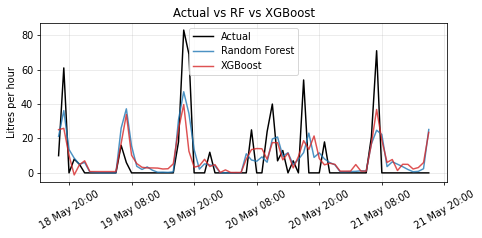

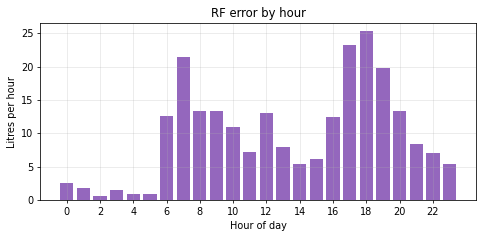

Top 5 largest errors (Random Forest):
                     actual    rf        xgb  rf_abs_err
timestamp                                               
2021-06-12 12:00:00   202.0  15.1  17.400000       186.9
2021-06-08 13:00:00   143.0   1.0   2.000000       142.0
2021-05-28 18:00:00   153.0  26.2  30.600000       126.8
2021-05-23 09:00:00   142.0  24.8  34.900002       117.2
2021-05-29 16:00:00   109.0   7.4  11.300000       101.6


In [23]:
import matplotlib.dates as mdates

# Smaller figures in Colab
plt.rcParams["figure.dpi"] = 70
plt.rcParams["figure.figsize"] = (7, 3.5)

# Prediction errors on the test set
err = pd.DataFrame({
    "actual": y_test.values,
    "rf": rf_pred,
    "xgb": xgb_pred,
}, index=test.index)
err["rf_abs_err"] = (err["actual"] - err["rf"]).abs()

n = 24 * 3

# Graph 1: Actual vs RF vs XGBoost
fig1, ax1 = plt.subplots()
ax1.plot(err.index[:n], err["actual"].values[:n], label="Actual", color="black", linewidth=1.5)
ax1.plot(err.index[:n], err["rf"].values[:n], label="Random Forest", color="#1f77b4", alpha=0.8)
ax1.plot(err.index[:n], err["xgb"].values[:n], label="XGBoost", color="#d62728", alpha=0.8)
ax1.set_title("Actual vs RF vs XGBoost")
ax1.set_ylabel("Litres per hour")
ax1.xaxis.set_major_locator(mdates.HourLocator(interval=12))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
ax1.tick_params(axis="x", rotation=30)
ax1.legend()
ax1.grid(True, alpha=0.3)
fig1.tight_layout()
plt.show()

# Graph 2: Average error by hour
hourly_err = err.groupby(err.index.hour)["rf_abs_err"].mean()
fig2, ax2 = plt.subplots()
ax2.bar(hourly_err.index, hourly_err.values, color="#9467bd")
ax2.set_title("RF error by hour")
ax2.set_xlabel("Hour of day")
ax2.set_ylabel("Litres per hour")
ax2.set_xticks(range(0, 24, 2))
ax2.grid(True, alpha=0.3)
fig2.tight_layout()
plt.show()

# Top 5 worst predictions
print("Top 5 largest errors (Random Forest):")
print(err.sort_values("rf_abs_err", ascending=False).head(5).round(1))

In [24]:
pred_df = pd.DataFrame({
    "timestamp": test.index,
    "block": "hh-01",
    "actual": y_test.values,
    "predicted": np.clip(rf_pred, 0, None).round(2),
})

os.makedirs("data", exist_ok=True)
pred_df.to_csv("data/predictions.csv", index=False)

print("Saved:", pred_df.shape)
print(pred_df.head(5))
print(pred_df.tail(3))

Saved: (884, 4)
            timestamp  block  actual  predicted
0 2021-05-18 18:00:00  hh-01    10.0      21.21
1 2021-05-18 19:00:00  hh-01    61.0      36.19
2 2021-05-18 20:00:00  hh-01     0.0      13.61
3 2021-05-18 21:00:00  hh-01     8.0       8.57
4 2021-05-18 22:00:00  hh-01     5.0       4.97
              timestamp  block  actual  predicted
881 2021-06-24 11:00:00  hh-01     0.0       1.05
882 2021-06-24 12:00:00  hh-01     0.0       1.09
883 2021-06-24 13:00:00  hh-01     0.0       1.00


In [25]:
# Threshold from TRAIN errors (RF predictions on train data)
train_pred = rf.predict(X_train)
train_err = (y_train.values - train_pred)
thr = np.percentile(train_err, 99)
print("Spike threshold (litres above prediction):", round(thr, 1))

alerts = pred_df.copy()
alerts["residual"] = alerts["actual"] - alerts["predicted"]

# 1) Spike: actual is far above prediction
spike = alerts["residual"] > thr

# 2) Night leak: 3 or more consecutive night hours (0-5) with flow
hour = alerts["timestamp"].dt.hour
night_flow = ((hour <= 5) & (alerts["actual"] > 0)).astype(int)
run = night_flow.groupby((night_flow == 0).cumsum()).cumsum()
leak = run >= 3

alerts["is_anomaly"] = (spike | leak).astype(int)
alerts["anomaly_score"] = alerts["residual"].clip(lower=0).round(2)
alerts["alert_type"] = np.where(leak, "night_leak", np.where(spike, "spike", ""))

alerts = alerts[["timestamp", "block", "actual", "predicted",
                 "is_anomaly", "anomaly_score", "alert_type"]]
alerts.to_csv("data/alerts.csv", index=False)

print("Saved:", alerts.shape)
print("Total alerts:", alerts["is_anomaly"].sum())
print(alerts["alert_type"].value_counts())
print(alerts[alerts["is_anomaly"] == 1].head(8))

Spike threshold (litres above prediction): 81.1
Saved: (884, 7)
Total alerts: 6
alert_type
         878
spike      6
Name: count, dtype: int64
              timestamp  block  actual  predicted  is_anomaly  anomaly_score  \
111 2021-05-23 09:00:00  hh-01   142.0      24.77           1         117.23   
240 2021-05-28 18:00:00  hh-01   153.0      26.19           1         126.81   
262 2021-05-29 16:00:00  hh-01   109.0       7.44           1         101.56   
431 2021-06-05 17:00:00  hh-01   104.0      15.29           1          88.71   
499 2021-06-08 13:00:00  hh-01   143.0       0.97           1         142.03   
594 2021-06-12 12:00:00  hh-01   202.0      15.13           1         186.87   

    alert_type  
111      spike  
240      spike  
262      spike  
431      spike  
499      spike  
594      spike  


In [28]:
np.random.seed(42)
thr = 81.1  # spike threshold from Step 18

sim = pred_df.copy()
sim["actual"] = sim["actual"].astype(float)
sim["is_leak"] = 0

# Pick 5 different nights (starting at hour 0) and add a 6-hour leak
starts = sim.index[(sim["timestamp"].dt.hour == 0) & (sim.index + 6 <= len(sim))]
starts = np.random.choice(starts, 5, replace=False)
sizes = [5, 10, 15, 20, 30]  # extra litres per hour

for s, size in zip(starts, sizes):
    sim.loc[s:s + 5, "actual"] += size
    sim.loc[s:s + 5, "is_leak"] = 1

# Same detector as Step 18
sim["residual"] = sim["actual"] - sim["predicted"]
spike = sim["residual"] > thr
hour = sim["timestamp"].dt.hour
night_flow = ((hour <= 5) & (sim["actual"] > 0)).astype(int)
run = night_flow.groupby((night_flow == 0).cumsum()).cumsum()
leak = run >= 3
sim["flag"] = (spike | leak).astype(int)

# Event level: was each injected leak caught?
print("Leak size (L/h) | caught?")
caught = 0
for s, size in zip(starts, sizes):
    hit = sim.loc[s:s + 5, "flag"].sum() > 0
    caught += int(hit)
    print(size, "|", "YES" if hit else "NO")

# Hour level
tp = ((sim["flag"] == 1) & (sim["is_leak"] == 1)).sum()
fp = ((sim["flag"] == 1) & (sim["is_leak"] == 0)).sum()
fn = ((sim["flag"] == 0) & (sim["is_leak"] == 1)).sum()
print("Events caught:", caught, "of 5")
print("Hour-level precision:", round(tp / (tp + fp), 2) if tp + fp else 0)
print("Hour-level recall   :", round(tp / (tp + fn), 2))
print("TP:", tp, "FP:", fp, "FN:", fn)

Leak size (L/h) | caught?
5 | YES
10 | YES
15 | YES
20 | YES
30 | YES
Events caught: 5 of 5
Hour-level precision: 0.77
Hour-level recall   : 0.67
TP: 20 FP: 6 FN: 10


               Model    MAE   RMSE  MAE improvement %  RMSE improvement %
0  Baseline (lag_24)  12.29  26.43               -0.0                -0.0
1      Random Forest   9.78  18.28               20.4                30.8
2            XGBoost   9.78  18.32               20.4                30.7


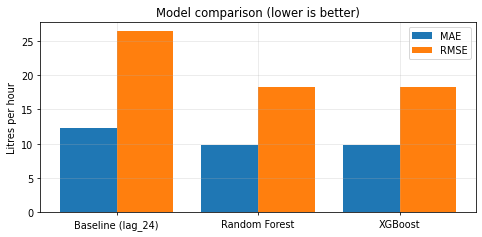

In [29]:
res = pd.DataFrame({
    "Model": ["Baseline (lag_24)", "Random Forest", "XGBoost"],
    "MAE": [mae, mae_rf, mae_xgb],
    "RMSE": [rmse, rmse_rf, rmse_xgb],
}).round(2)

res["MAE improvement %"] = ((mae - res["MAE"]) / mae * 100).round(1)
res["RMSE improvement %"] = ((rmse - res["RMSE"]) / rmse * 100).round(1)

os.makedirs("data", exist_ok=True)
res.to_csv("data/model_comparison.csv", index=False)
print(res)

plt.rcParams["figure.dpi"] = 70
fig, ax = plt.subplots(figsize=(7, 3.5))
pos = np.arange(len(res))
ax.bar(pos - 0.2, res["MAE"], width=0.4, label="MAE", color="#1f77b4")
ax.bar(pos + 0.2, res["RMSE"], width=0.4, label="RMSE", color="#ff7f0e")
ax.set_xticks(pos)
ax.set_xticklabels(res["Model"])
ax.set_ylabel("Litres per hour")
ax.set_title("Model comparison (lower is better)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [30]:
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(rf, "models/random_forest.pkl")
xgb.save_model("models/xgboost.json")

print(os.listdir("models"))
print(os.listdir("data"))

['random_forest.pkl', 'xgboost.json']
['water_hourly.csv', 'predictions.csv', 'alerts.csv', 'model_comparison.csv']


In [32]:
# Walk-forward (expanding window) backtest
# Every prediction comes from a model trained only on PAST data.
from sklearn.ensemble import RandomForestRegressor
from google.colab import files

INIT = 168 * 6   # first 6 weeks are used only to train the first model
STEP = 168       # retrain every week
THR = 81.1       # spike threshold (same as the report)
target = "consumption_litres"

rows = []
for start in range(INIT, len(feat), STEP):
    tr = feat.iloc[:start]
    te = feat.iloc[start:start + STEP]
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                              random_state=42, n_jobs=-1)
    m.fit(tr[features], tr[target])
    p = np.clip(m.predict(te[features]), 0, None).round(2)
    rows.append(pd.DataFrame({
        "timestamp": te.index, "block": "hh-01",
        "actual": te[target].values, "predicted": p,
        "baseline": te["lag_24"].values,
    }))

bt = pd.concat(rows, ignore_index=True)

# Alerts (same rules as before)
al = bt.copy()
al["residual"] = al["actual"] - al["predicted"]
spike = al["residual"] > THR
hour = al["timestamp"].dt.hour
night_flow = ((hour <= 5) & (al["actual"] > 0)).astype(int)
run = night_flow.groupby((night_flow == 0).cumsum()).cumsum()
leak = run >= 3
al["is_anomaly"] = (spike | leak).astype(int)
al["anomaly_score"] = al["residual"].clip(lower=0).round(2)
al["alert_type"] = np.where(leak, "night_leak", np.where(spike, "spike", ""))
al = al[["timestamp", "block", "actual", "predicted", "baseline",
         "is_anomaly", "anomaly_score", "alert_type"]]

bt.to_csv("data/predictions_walkforward.csv", index=False)
al.to_csv("data/alerts_walkforward.csv", index=False)

# Checks
e = bt["actual"] - bt["predicted"]
b = bt["actual"] - bt["baseline"]
print("Rows:", len(bt), "|", bt["timestamp"].min(), "to", bt["timestamp"].max())
print("Walk-forward RF -> MAE:", round(e.abs().mean(), 2), "| RMSE:", round((e**2).mean()**0.5, 2))
print("Baseline lag_24 -> MAE:", round(b.abs().mean(), 2), "| RMSE:", round((b**2).mean()**0.5, 2))
print(al["alert_type"].replace("", "none").value_counts())

files.download("data/predictions_walkforward.csv")
files.download("data/alerts_walkforward.csv")

Rows: 3412 | 2021-02-02 09:00:00 to 2021-06-24 13:00:00
Walk-forward RF -> MAE: 10.74 | RMSE: 20.39
Baseline lag_24 -> MAE: 12.9 | RMSE: 28.27
alert_type
none          3372
spike           34
night_leak       6
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
%cd /content/drive/MyDrive/watertwin
!ls | grep -i "hh-\?15"
!unzip -q -o hh-15.zip -d hh-15
!find hh-15 | head -20

/content/drive/MyDrive/watertwin
hh-15.zip
hh-15
hh-15/hh-15
hh-15/hh-15/smartmeter.csv
hh-15/hh-15/info.txt
hh-15/hh-15/info.json
hh-15/__MACOSX
hh-15/__MACOSX/._hh-15
hh-15/__MACOSX/hh-15
hh-15/__MACOSX/hh-15/._smartmeter.csv
hh-15/__MACOSX/hh-15/._info.txt
hh-15/__MACOSX/hh-15/._info.json


In [38]:
import os, glob
import numpy as np
import pandas as pd

%cd /content/drive/MyDrive/watertwin

MAX_FILL_HOURS = 6   # fill only short gaps; longer gaps stay empty (NaN)
frames, rows = [], []

for p in sorted(glob.glob("hh-*/**/smartmeter.csv", recursive=True)):
    h = p.split("/")[0]
    d = pd.read_csv(p)
    d["time"] = pd.to_datetime(d["time"], utc=True)
    d = d.sort_values("time")

    # size of reading drops, in litres (checked BEFORE cummax)
    dd = d["total_m3"].diff() * 1000
    max_drop = round(float(-dd.min()), 1) if dd.min() < 0 else 0.0
    big_drops = int((dd < -50).sum())

    s = d.set_index("time")["total_m3"].cummax()     # remove small flicker
    hourly = s.resample("1h").last()

    # fill short gaps only
    isna = hourly.isna()
    run_id = (isna != isna.shift()).cumsum()
    gap_len = isna.groupby(run_id).transform("sum")
    filled = hourly.interpolate(limit_area="inside")
    hourly = filled.where(~(isna & (gap_len > MAX_FILL_HOURS)))

    cons = (hourly.diff() * 1000).iloc[1:]           # litres per hour
    out = cons.reset_index()
    out.columns = ["timestamp_utc", "consumption_litres"]
    out["timestamp"] = (out["timestamp_utc"].dt.tz_convert("Europe/Berlin")
                        .dt.tz_localize(None))
    out["block"] = h
    out = out[["timestamp_utc", "timestamp", "block", "consumption_litres"]]
    frames.append(out)

    c = out["consumption_litres"]
    rows.append({
        "household": h,
        "hours": len(out),
        "missing_hours": int(c.isna().sum()),
        "coverage_%": round(100 * c.notna().mean(), 1),
        "mean_L_per_h": round(c.mean(), 2),
        "max_L_per_h": round(c.max(), 1),
        "zero_%": round(100 * (c == 0).sum() / c.notna().sum(), 1),
        "drops": int((dd < 0).sum()),
        "max_drop_L": max_drop,
        "drops_over_50L": big_drops,
    })

all_hourly = pd.concat(frames, ignore_index=True)
os.makedirs("data", exist_ok=True)
all_hourly.to_csv("data/water_hourly_all.csv", index=False)

print("Saved:", all_hourly.shape)
print(pd.DataFrame(rows).to_string(index=False))

/content/drive/MyDrive/watertwin
Saved: (162226, 4)
household  hours  missing_hours  coverage_%  mean_L_per_h  max_L_per_h  zero_%  drops  max_drop_L  drops_over_50L
    hh-01   4588              0       100.0          9.69        285.0    59.4      2        19.0               0
    hh-02   8832           4502        49.0         22.70      24398.0    19.7    124        13.0               0
    hh-03   5623           1953        65.3         12.76      15624.0    47.2     27     15593.0               2
    hh-04  12770          11241        12.0         41.02      16689.7    27.8     26        59.0               3
    hh-05  11456           2014        82.4         16.65        430.0    22.4    129        45.0               0
    hh-06   5828            938        83.9         12.76       5655.0    41.7    411      5655.0              53
    hh-07   4437              0       100.0          8.91        257.0    36.4     21         4.0               0
    hh-08  18156           4143     

In [39]:
import glob
import pandas as pd

%cd /content/drive/MyDrive/watertwin

def look(h, kind):
    p = glob.glob(f"{h}/**/smartmeter.csv", recursive=True)[0]
    d = pd.read_csv(p)
    d["time"] = pd.to_datetime(d["time"], utc=True)
    d = d.sort_values("time").reset_index(drop=True)
    d["jump_L"] = d["total_m3"].diff() * 1000
    i = d["jump_L"].idxmin() if kind == "drop" else d["jump_L"].idxmax()
    print("=====", h, "| biggest", kind, "at", d.loc[i, "time"])
    print(d.loc[i - 4:i + 4, ["time", "total_m3", "jump_L"]].round(3).to_string())
    if kind == "drop":
        v = d.loc[i, "total_m3"]
        before = d.loc[:i - 1]
        j = before.index[before["total_m3"] <= v + 0.001].max()
        print("High reading lasted from", d.loc[j + 1, "time"], "to", d.loc[i, "time"],
              "=", d.loc[i, "time"] - d.loc[j + 1, "time"])

for h, k in [("hh-03", "drop"), ("hh-06", "drop"), ("hh-02", "rise")]:
    look(h, k)

/content/drive/MyDrive/watertwin
===== hh-03 | biggest drop at 2021-06-03 16:31:46+00:00
                            time  total_m3   jump_L
586714 2021-06-03 16:30:58+00:00   123.352      0.0
586715 2021-06-03 16:31:10+00:00   123.352      0.0
586716 2021-06-03 16:31:22+00:00   138.945  15593.0
586717 2021-06-03 16:31:32+00:00   138.945      0.0
586718 2021-06-03 16:31:46+00:00   123.352 -15593.0
586719 2021-06-03 16:32:58+00:00   123.352      0.0
586720 2021-06-03 16:33:21+00:00   123.352      0.0
586721 2021-06-03 16:34:09+00:00   123.352      0.0
586722 2021-06-03 16:34:33+00:00   123.352      0.0
High reading lasted from 2021-06-03 16:31:22+00:00 to 2021-06-03 16:31:46+00:00 = 0 days 00:00:24
===== hh-06 | biggest drop at 2021-06-09 12:43:26+00:00
                            time  total_m3  jump_L
702335 2021-06-09 12:43:14+00:00   120.913     0.0
702336 2021-06-09 12:43:23+00:00   126.561  5648.0
702337 2021-06-09 12:43:24+00:00   126.561     0.0
702338 2021-06-09 12:43:25+00:00 

In [40]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/watertwin")
summary_rows = []

for household_id in [f"hh-{i:02d}" for i in range(1, 18)]:
    file_path = ROOT / household_id / household_id / "smartmeter.csv"

    readings = pd.read_csv(file_path, usecols=["time"])
    timestamps = pd.to_datetime(
        readings["time"], utc=True, errors="coerce"
    ).dropna().sort_values()

    gaps_seconds = timestamps.diff().dt.total_seconds().dropna()

    summary_rows.append({
        "household": household_id,
        "readings": len(timestamps),
        "median_gap_sec": round(gaps_seconds.median(), 1),
        "p99_gap_sec": round(gaps_seconds.quantile(0.99), 1),
        "gaps_over_1_min": int((gaps_seconds > 60).sum()),
        "gaps_over_5_min": int((gaps_seconds > 300).sum()),
        "gaps_over_1_hour": int((gaps_seconds > 3600).sum()),
        "largest_gap_hours": round(gaps_seconds.max() / 3600, 2),
    })

gap_summary = pd.DataFrame(summary_rows)
display(gap_summary)

,household,readings,median_gap_sec,p99_gap_sec,gaps_over_1_min,gaps_over_5_min,gaps_over_1_hour,largest_gap_hours
0,hh-01,1388374,12.0,23.0,129,32,3,1.59
1,hh-02,1314504,12.0,19.0,63,19,11,1827.45
2,hh-03,926611,12.0,36.0,4188,1139,54,1754.73
3,hh-04,145515,12.0,355.0,9043,1709,165,6178.54
4,hh-05,2861708,12.0,23.0,15,8,4,1973.63
5,hh-06,1484185,12.0,23.0,24,13,6,485.26
6,hh-07,1341377,12.0,24.0,163,12,0,0.94
7,hh-08,3896681,12.0,24.0,7546,1676,193,2314.69
8,hh-09,944727,12.0,47.0,5361,1306,138,4498.23
9,hh-10,1956478,12.0,13.0,48,18,6,556.99


In [41]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/watertwin")
MAX_EVENT_DURATION = pd.Timedelta(minutes=5)

event_rows = []

for household_id in [f"hh-{i:02d}" for i in range(1, 18)]:
    file_path = ROOT / household_id / household_id / "smartmeter.csv"

    meter = pd.read_csv(file_path, usecols=["time", "total_m3"])
    meter["time"] = pd.to_datetime(meter["time"], utc=True, errors="coerce")
    meter = meter.dropna().sort_values("time").reset_index(drop=True)

    meter["total_litres"] = meter["total_m3"] * 1000
    jumps = meter["total_litres"].diff().fillna(0).to_numpy()
    timestamps = meter["time"].to_numpy()

    negative_indices = np.flatnonzero(jumps < 0)

    for index in negative_indices:
        event_start_time = timestamps[index] - MAX_EVENT_DURATION
        start_index = timestamps.searchsorted(event_start_time, side="left")

        recent_jumps = jumps[start_index:index + 1]
        positive_total = recent_jumps[recent_jumps > 0].sum()
        negative_jump = jumps[index]

        tolerance_litres = max(2, abs(negative_jump) * 0.01)

        if (
            positive_total > 0
            and abs(positive_total + negative_jump) <= tolerance_litres
        ):
            event_rows.append({
                "household": household_id,
                "event_start": meter.loc[start_index, "time"],
                "event_end": meter.loc[index, "time"],
                "duration_seconds": round(
                    (meter.loc[index, "time"] - meter.loc[start_index, "time"])
                    .total_seconds(), 1
                ),
                "false_rise_litres": round(positive_total, 1),
                "negative_correction_litres": round(negative_jump, 1),
            })

excursion_events = pd.DataFrame(event_rows)

event_summary = (
    excursion_events.groupby("household", as_index=False)
    .agg(
        temporary_glitch_events=("household", "size"),
        total_invalid_litres=("false_rise_litres", "sum"),
        largest_invalid_event_litres=("false_rise_litres", "max"),
    )
)

display(event_summary)
display(excursion_events.sort_values(
    ["false_rise_litres", "household"],
    ascending=[False, True]
).head(30))

,household,temporary_glitch_events,total_invalid_litres,largest_invalid_event_litres
0,hh-01,1,19.0,19.0
1,hh-02,2,27.0,15.0
2,hh-03,5,15751.0,15607.0
3,hh-04,4,124.0,60.0
4,hh-05,4,61.0,39.0
5,hh-06,16,5751.0,5655.0
6,hh-07,1,4.0,4.0
7,hh-08,10,3338.0,1473.0
8,hh-09,1,1063.0,1063.0
9,hh-10,2,6637.0,6629.0


,household,event_start,event_end,duration_seconds,false_rise_litres,negative_correction_litres
6,hh-03,2021-06-03 16:27:36+00:00,2021-06-03 16:31:46+00:00,250.0,15607.0,-15593.0
70,hh-15,2022-06-20 07:45:11+00:00,2022-06-20 07:50:08+00:00,297.0,12092.0,-12091.0
45,hh-10,2021-08-13 09:12:25+00:00,2021-08-13 09:17:23+00:00,298.0,6629.0,-6629.0
23,hh-06,2021-06-09 12:38:30+00:00,2021-06-09 12:43:26+00:00,296.0,5655.0,-5655.0
56,hh-12,2021-06-29 17:12:22+00:00,2021-06-29 17:17:19+00:00,297.0,3183.0,-3183.0
69,hh-15,2021-07-08 15:23:25+00:00,2021-07-08 15:28:22+00:00,297.0,2274.0,-2274.0
38,hh-08,2021-07-08 15:24:14+00:00,2021-07-08 15:29:11+00:00,297.0,1473.0,-1464.0
35,hh-08,2021-05-01 20:27:06+00:00,2021-05-01 20:32:04+00:00,298.0,1268.0,-1268.0
43,hh-09,2022-04-16 08:14:14+00:00,2022-04-16 08:18:48+00:00,274.0,1063.0,-1063.0
57,hh-14,2021-06-23 20:12:28+00:00,2021-06-23 20:17:24+00:00,296.0,901.0,-901.0


In [43]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/watertwin")
OUTPUT_DIR = ROOT / "data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_GAP_SECONDS = 300
MIN_READINGS_PER_HOUR = 30
MIN_OBSERVED_MINUTES = 45
EVENT_WINDOW = pd.Timedelta(minutes=5)
LOCAL_TIMEZONE = "Europe/Berlin"

all_hourly = []
cleaning_summary_rows = []

for household_id in [f"hh-{i:02d}" for i in range(1, 18)]:
    file_path = ROOT / household_id / household_id / "smartmeter.csv"

    meter = pd.read_csv(file_path, usecols=["time", "total_m3"])
    meter["time"] = pd.to_datetime(meter["time"], utc=True, errors="coerce")
    meter = meter.dropna().sort_values("time").reset_index(drop=True)

    meter["total_litres"] = meter["total_m3"] * 1000
    meter["jump_litres"] = meter["total_litres"].diff().fillna(0)
    meter["gap_seconds"] = meter["time"].diff().dt.total_seconds()

    # Hour grouping is performed in UTC to preserve daylight-saving transitions.
    meter["hour_utc"] = meter["time"].dt.floor("h")

    timestamps = pd.DatetimeIndex(meter["time"])
    jumps = meter["jump_litres"].to_numpy()

    meter["excursion_affected"] = False
    gap_affected_hours = set()
    event_affected_hours = set()
    temporary_event_count = 0

    long_gap_indices = np.flatnonzero(
        meter["gap_seconds"].to_numpy() > MAX_GAP_SECONDS
    )

    for index in long_gap_indices:
        gap_affected_hours.add(meter.loc[index - 1, "hour_utc"])
        gap_affected_hours.add(meter.loc[index, "hour_utc"])

    negative_indices = np.flatnonzero(jumps < 0)

    for index in negative_indices:
        start_time = timestamps[index] - EVENT_WINDOW
        start_index = timestamps.searchsorted(start_time, side="left")

        recent_jumps = jumps[start_index:index + 1]
        positive_total = recent_jumps[recent_jumps > 0].sum()
        negative_jump = jumps[index]
        tolerance_litres = max(2, abs(negative_jump) * 0.01)

        is_temporary_excursion = (
            positive_total > 0
            and abs(positive_total + negative_jump) <= tolerance_litres
        )

        if is_temporary_excursion:
            meter.loc[start_index:index, "excursion_affected"] = True
            event_affected_hours.update(
                meter.loc[start_index:index, "hour_utc"].unique()
            )
            temporary_event_count += 1

    meter["valid_positive_increment"] = meter["jump_litres"].clip(lower=0)

    meter.loc[
        meter["gap_seconds"] > MAX_GAP_SECONDS,
        "valid_positive_increment",
    ] = 0

    meter.loc[
        meter["excursion_affected"],
        "valid_positive_increment",
    ] = 0

    hourly = (
        meter.groupby("hour_utc")
        .agg(
            consumption_litres=("valid_positive_increment", "sum"),
            reading_count=("time", "size"),
            first_reading=("time", "min"),
            last_reading=("time", "max"),
        )
    )

    full_hours = pd.date_range(
        meter["hour_utc"].min(),
        meter["hour_utc"].max(),
        freq="h",
        tz="UTC",
    )

    hourly = hourly.reindex(full_hours)
    hourly.index.name = "timestamp_utc"

    hourly["observed_minutes"] = (
        (hourly["last_reading"] - hourly["first_reading"])
        .dt.total_seconds()
        .div(60)
    )

    hourly["gap_affected"] = hourly.index.isin(gap_affected_hours)
    hourly["excursion_affected"] = hourly.index.isin(event_affected_hours)

    hourly["valid_hour"] = (
        hourly["reading_count"].ge(MIN_READINGS_PER_HOUR)
        & hourly["observed_minutes"].ge(MIN_OBSERVED_MINUTES)
        & ~hourly["gap_affected"]
        & ~hourly["excursion_affected"]
    )

    hourly["invalid_reason"] = ""
    hourly.loc[
        hourly["reading_count"].isna(),
        "invalid_reason",
    ] = "No readings"

    hourly.loc[
        hourly["gap_affected"],
        "invalid_reason",
    ] = "Long data gap"

    hourly.loc[
        hourly["excursion_affected"],
        "invalid_reason",
    ] = "Temporary meter glitch"

    incomplete_coverage = (
        hourly["reading_count"].notna()
        & ~hourly["valid_hour"]
        & ~hourly["gap_affected"]
        & ~hourly["excursion_affected"]
    )

    hourly.loc[
        incomplete_coverage,
        "invalid_reason",
    ] = "Insufficient within-hour coverage"

    hourly["consumption_litres"] = hourly["consumption_litres"].where(
        hourly["valid_hour"]
    )

    hourly = hourly.reset_index()
    hourly["timestamp"] = hourly["timestamp_utc"].dt.tz_convert(
        LOCAL_TIMEZONE
    )
    hourly["household"] = household_id

    all_hourly.append(hourly)

    cleaning_summary_rows.append({
        "household": household_id,
        "raw_readings": len(meter),
        "total_hours": len(hourly),
        "valid_hours": int(hourly["valid_hour"].sum()),
        "invalid_hours": int((~hourly["valid_hour"]).sum()),
        "coverage_percent": round(hourly["valid_hour"].mean() * 100, 2),
        "long_gap_boundaries": int(len(long_gap_indices)),
        "temporary_glitch_events": temporary_event_count,
        "temporary_glitch_hours": int(hourly["excursion_affected"].sum()),
    })

water_hourly_cleaned_all = pd.concat(all_hourly, ignore_index=True)
cleaning_summary = pd.DataFrame(cleaning_summary_rows)

water_hourly_cleaned_all.to_csv(
    OUTPUT_DIR / "water_hourly_cleaned_all.csv",
    index=False,
)

cleaning_summary.to_csv(
    OUTPUT_DIR / "water_cleaning_summary.csv",
    index=False,
)

display(cleaning_summary)

hh01_check = water_hourly_cleaned_all[
    water_hourly_cleaned_all["household"].eq("hh-01")
]

display(
    hh01_check[
        [
            "timestamp",
            "consumption_litres",
            "valid_hour",
            "invalid_reason",
        ]
    ].tail(10)
)

print("Saved:", OUTPUT_DIR / "water_hourly_cleaned_all.csv")
print("Saved:", OUTPUT_DIR / "water_cleaning_summary.csv")

,household,raw_readings,total_hours,valid_hours,invalid_hours,coverage_percent,long_gap_boundaries,temporary_glitch_events,temporary_glitch_hours
0,hh-01,1388374,4589,4569,20,99.56,32,1,1
1,hh-02,1314504,8833,4309,4524,48.78,19,2,2
2,hh-03,926611,5624,2876,2748,51.14,1139,5,3
3,hh-04,145515,12771,670,12101,5.25,1709,4,4
4,hh-05,2861708,11457,9430,2027,82.31,8,4,3
5,hh-06,1484185,5829,4864,965,83.44,13,16,10
6,hh-07,1341377,4438,4425,13,99.71,12,1,1
7,hh-08,3896681,18157,12784,5373,70.41,1676,10,9
8,hh-09,944727,13155,2938,10217,22.33,1306,1,1
9,hh-10,1956478,7670,6409,1261,83.56,18,2,2


,timestamp,consumption_litres,valid_hour,invalid_reason
4579,2021-06-24 04:00:00+02:00,0.0,True,
4580,2021-06-24 05:00:00+02:00,0.0,True,
4581,2021-06-24 06:00:00+02:00,12.0,True,
4582,2021-06-24 07:00:00+02:00,88.0,True,
4583,2021-06-24 08:00:00+02:00,0.0,True,
4584,2021-06-24 09:00:00+02:00,0.0,True,
4585,2021-06-24 10:00:00+02:00,0.0,True,
4586,2021-06-24 11:00:00+02:00,0.0,True,
4587,2021-06-24 12:00:00+02:00,0.0,True,
4588,2021-06-24 13:00:00+02:00,0.0,True,


Saved: /content/drive/MyDrive/watertwin/data/water_hourly_cleaned_all.csv
Saved: /content/drive/MyDrive/watertwin/data/water_cleaning_summary.csv


In [44]:
import pandas as pd
from pathlib import Path

CLEANED_FILE = Path(
    "/content/drive/MyDrive/watertwin/data/water_hourly_cleaned_all.csv"
)

cleaned = pd.read_csv(CLEANED_FILE)

valid = cleaned[
    cleaned["valid_hour"].eq(True)
    & cleaned["consumption_litres"].notna()
].copy()

quality_summary = (
    valid.groupby("household")
    .agg(
        valid_hours=("consumption_litres", "size"),
        mean_litres_per_hour=("consumption_litres", "mean"),
        median_litres_per_hour=("consumption_litres", "median"),
        p99_litres_per_hour=(
            "consumption_litres",
            lambda values: values.quantile(0.99),
        ),
        max_litres_per_hour=("consumption_litres", "max"),
        zero_hour_percent=(
            "consumption_litres",
            lambda values: (values.eq(0).mean() * 100),
        ),
    )
    .reset_index()
)

quality_summary["mean_litres_per_hour"] = (
    quality_summary["mean_litres_per_hour"].round(2)
)
quality_summary["median_litres_per_hour"] = (
    quality_summary["median_litres_per_hour"].round(2)
)
quality_summary["p99_litres_per_hour"] = (
    quality_summary["p99_litres_per_hour"].round(2)
)
quality_summary["zero_hour_percent"] = (
    quality_summary["zero_hour_percent"].round(2)
)

display(quality_summary)

largest_clean_hours = (
    valid[
        [
            "household",
            "timestamp",
            "consumption_litres",
        ]
    ]
    .sort_values("consumption_litres", ascending=False)
    .head(30)
)

display(largest_clean_hours)

,household,valid_hours,mean_litres_per_hour,median_litres_per_hour,p99_litres_per_hour,max_litres_per_hour,zero_hour_percent
0,hh-01,4569,9.72,0.0,127.32,285.0,59.27
1,hh-02,4309,17.12,10.0,114.92,283.0,19.66
2,hh-03,2876,8.15,1.0,80.00,188.0,49.65
3,hh-04,670,8.02,4.0,39.00,53.0,33.73
4,hh-05,9430,16.67,8.0,114.00,430.0,22.45
5,hh-06,4864,11.66,5.0,74.00,280.0,41.80
6,hh-07,4425,8.93,4.0,56.76,257.0,36.36
7,hh-08,12784,20.85,12.0,114.00,407.0,18.67
8,hh-09,2938,29.91,19.5,147.26,270.0,19.81
9,hh-10,6409,10.09,3.0,94.92,873.0,39.65


,household,timestamp,consumption_litres
123125,hh-14,2021-06-23 23:00:00+02:00,29627.0
107428,hh-11,2022-06-06 10:00:00+02:00,1170.0
107431,hh-11,2022-06-06 13:00:00+02:00,1168.0
107432,hh-11,2022-06-06 14:00:00+02:00,1167.0
107434,hh-11,2022-06-06 16:00:00+02:00,1161.0
107433,hh-11,2022-06-06 15:00:00+02:00,1159.0
107429,hh-11,2022-06-06 11:00:00+02:00,1159.0
107430,hh-11,2022-06-06 12:00:00+02:00,1153.0
107427,hh-11,2022-06-06 09:00:00+02:00,1152.0
107426,hh-11,2022-06-06 08:00:00+02:00,1133.0


In [45]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/watertwin")
LOCAL_TIMEZONE = "Europe/Berlin"

inspection_cases = [
    {
        "household": "hh-14",
        "center_time": "2021-06-23 23:00:00",
        "window_minutes": 15,
    },
    {
        "household": "hh-11",
        "center_time": "2022-06-06 12:00:00",
        "window_minutes": 15,
    },
    {
        "household": "hh-13",
        "center_time": "2021-06-14 18:00:00",
        "window_minutes": 15,
    },
]

for case in inspection_cases:
    household_id = case["household"]
    file_path = ROOT / household_id / household_id / "smartmeter.csv"

    meter = pd.read_csv(file_path, usecols=["time", "total_m3"])
    meter["time"] = pd.to_datetime(meter["time"], utc=True, errors="coerce")
    meter = meter.dropna().sort_values("time").reset_index(drop=True)

    meter["time_local"] = meter["time"].dt.tz_convert(LOCAL_TIMEZONE)
    meter["total_litres"] = meter["total_m3"] * 1000
    meter["jump_litres"] = meter["total_litres"].diff().fillna(0)

    center_time = pd.Timestamp(
        case["center_time"],
        tz=LOCAL_TIMEZONE,
    )

    start_time = center_time - pd.Timedelta(
        minutes=case["window_minutes"]
    )
    end_time = center_time + pd.Timedelta(
        minutes=case["window_minutes"]
    )

    window = meter[
        meter["time_local"].between(start_time, end_time)
    ]

    print(f"\n===== {household_id} =====")
    print(
        window[
            ["time_local", "total_m3", "jump_litres"]
        ].to_string(index=False)
    )


===== hh-14 =====
               time_local  total_m3  jump_litres
2021-06-23 22:45:01+02:00    92.100        901.0
2021-06-23 22:45:02+02:00    91.199       -901.0
2021-06-23 22:45:12+02:00    92.100        901.0
2021-06-23 22:45:15+02:00    91.199       -901.0
2021-06-23 22:45:24+02:00    92.100        901.0
2021-06-23 22:45:26+02:00    91.199       -901.0
2021-06-23 22:45:36+02:00    92.100        901.0
2021-06-23 22:45:38+02:00    91.199       -901.0
2021-06-23 22:45:48+02:00    92.100        901.0
2021-06-23 22:46:00+02:00    92.100          0.0
2021-06-23 22:46:02+02:00    91.199       -901.0
2021-06-23 22:46:12+02:00    92.100        901.0
2021-06-23 22:46:14+02:00    91.199       -901.0
2021-06-23 22:46:24+02:00    92.100        901.0
2021-06-23 22:46:26+02:00    91.199       -901.0
2021-06-23 22:46:36+02:00    92.100        901.0
2021-06-23 22:46:38+02:00    91.199       -901.0
2021-06-23 22:46:47+02:00    92.100        901.0
2021-06-23 22:46:59+02:00    92.100          0.0
2

In [46]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/watertwin")
OUTPUT_DIR = ROOT / "data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_GAP_SECONDS = 300
MIN_READINGS_PER_HOUR = 30
MIN_OBSERVED_MINUTES = 45
EVENT_WINDOW = pd.Timedelta(minutes=5)
PAIR_WINDOW = pd.Timedelta(seconds=30)
LOCAL_TIMEZONE = "Europe/Berlin"

all_hourly = []
cleaning_summary_rows = []

for household_id in [f"hh-{i:02d}" for i in range(1, 18)]:
    file_path = ROOT / household_id / household_id / "smartmeter.csv"

    meter = pd.read_csv(file_path, usecols=["time", "total_m3"])
    meter["time"] = pd.to_datetime(meter["time"], utc=True, errors="coerce")
    meter = meter.dropna().sort_values("time").reset_index(drop=True)

    meter["total_litres"] = meter["total_m3"] * 1000
    meter["jump_litres"] = meter["total_litres"].diff().fillna(0)
    meter["gap_seconds"] = meter["time"].diff().dt.total_seconds()
    meter["hour_utc"] = meter["time"].dt.floor("h")
    meter["excursion_affected"] = False

    timestamps = pd.DatetimeIndex(meter["time"])
    jumps = meter["jump_litres"].to_numpy()
    negative_indices = np.flatnonzero(jumps < 0)

    gap_affected_hours = set()

    long_gap_indices = np.flatnonzero(
        meter["gap_seconds"].to_numpy() > MAX_GAP_SECONDS
    )

    for index in long_gap_indices:
        gap_affected_hours.add(meter.loc[index - 1, "hour_utc"])
        gap_affected_hours.add(meter.loc[index, "hour_utc"])

    # Detect a total positive rise that is reversed within five minutes.
    for index in negative_indices:
        start_time = timestamps[index] - EVENT_WINDOW
        start_index = timestamps.searchsorted(start_time, side="left")

        recent_jumps = jumps[start_index:index + 1]
        positive_total = recent_jumps[recent_jumps > 0].sum()
        negative_jump = jumps[index]
        tolerance_litres = max(2, abs(negative_jump) * 0.01)

        if (
            positive_total > 0
            and abs(positive_total + negative_jump) <= tolerance_litres
        ):
            meter.loc[start_index:index, "excursion_affected"] = True

    # Detect rapid repeated up-down meter oscillations.
    for index in negative_indices:
        start_time = timestamps[index] - PAIR_WINDOW
        start_index = timestamps.searchsorted(start_time, side="left")

        candidate_indices = np.arange(start_index, index)
        positive_indices = candidate_indices[
            jumps[candidate_indices] > 0
        ]

        if len(positive_indices) == 0:
            continue

        negative_jump = jumps[index]
        differences = np.abs(jumps[positive_indices] + negative_jump)
        best_position = differences.argmin()
        best_index = positive_indices[best_position]

        tolerance_litres = max(2, abs(negative_jump) * 0.01)

        if differences[best_position] <= tolerance_litres:
            meter.loc[best_index:index, "excursion_affected"] = True

    meter["valid_positive_increment"] = meter["jump_litres"].clip(lower=0)

    meter.loc[
        meter["gap_seconds"] > MAX_GAP_SECONDS,
        "valid_positive_increment",
    ] = 0

    meter.loc[
        meter["excursion_affected"],
        "valid_positive_increment",
    ] = 0

    event_affected_hours = set(
        meter.loc[
            meter["excursion_affected"],
            "hour_utc",
        ].unique()
    )

    affected_times = meter.loc[
        meter["excursion_affected"],
        "time",
    ]

    if len(affected_times) == 0:
        temporary_event_count = 0
    else:
        new_episode = (
            affected_times.diff().dt.total_seconds().fillna(
                MAX_GAP_SECONDS + 1
            ) > MAX_GAP_SECONDS
        )
        temporary_event_count = int(new_episode.sum())

    hourly = (
        meter.groupby("hour_utc")
        .agg(
            consumption_litres=("valid_positive_increment", "sum"),
            reading_count=("time", "size"),
            first_reading=("time", "min"),
            last_reading=("time", "max"),
        )
    )

    full_hours = pd.date_range(
        meter["hour_utc"].min(),
        meter["hour_utc"].max(),
        freq="h",
        tz="UTC",
    )

    hourly = hourly.reindex(full_hours)
    hourly.index.name = "timestamp_utc"

    hourly["observed_minutes"] = (
        (hourly["last_reading"] - hourly["first_reading"])
        .dt.total_seconds()
        .div(60)
    )

    hourly["gap_affected"] = hourly.index.isin(gap_affected_hours)
    hourly["excursion_affected"] = hourly.index.isin(event_affected_hours)

    hourly["valid_hour"] = (
        hourly["reading_count"].ge(MIN_READINGS_PER_HOUR)
        & hourly["observed_minutes"].ge(MIN_OBSERVED_MINUTES)
        & ~hourly["gap_affected"]
        & ~hourly["excursion_affected"]
    )

    hourly["invalid_reason"] = ""
    hourly.loc[
        hourly["reading_count"].isna(),
        "invalid_reason",
    ] = "No readings"

    hourly.loc[
        hourly["gap_affected"],
        "invalid_reason",
    ] = "Long data gap"

    hourly.loc[
        hourly["excursion_affected"],
        "invalid_reason",
    ] = "Temporary meter glitch"

    incomplete_coverage = (
        hourly["reading_count"].notna()
        & ~hourly["valid_hour"]
        & ~hourly["gap_affected"]
        & ~hourly["excursion_affected"]
    )

    hourly.loc[
        incomplete_coverage,
        "invalid_reason",
    ] = "Insufficient within-hour coverage"

    hourly["consumption_litres"] = hourly["consumption_litres"].where(
        hourly["valid_hour"]
    )

    hourly = hourly.reset_index()
    hourly["timestamp"] = hourly["timestamp_utc"].dt.tz_convert(
        LOCAL_TIMEZONE
    )
    hourly["household"] = household_id

    all_hourly.append(hourly)

    cleaning_summary_rows.append({
        "household": household_id,
        "raw_readings": len(meter),
        "total_hours": len(hourly),
        "valid_hours": int(hourly["valid_hour"].sum()),
        "invalid_hours": int((~hourly["valid_hour"]).sum()),
        "coverage_percent": round(hourly["valid_hour"].mean() * 100, 2),
        "long_gap_boundaries": int(len(long_gap_indices)),
        "temporary_glitch_events": temporary_event_count,
        "temporary_glitch_hours": int(hourly["excursion_affected"].sum()),
    })

water_hourly_cleaned_all = pd.concat(all_hourly, ignore_index=True)
cleaning_summary = pd.DataFrame(cleaning_summary_rows)

water_hourly_cleaned_all.to_csv(
    OUTPUT_DIR / "water_hourly_cleaned_all.csv",
    index=False,
)

cleaning_summary.to_csv(
    OUTPUT_DIR / "water_cleaning_summary.csv",
    index=False,
)

display(cleaning_summary)

hh14_check = water_hourly_cleaned_all[
    water_hourly_cleaned_all["household"].eq("hh-14")
    & water_hourly_cleaned_all["timestamp"].between(
        "2021-06-23 22:00:00+02:00",
        "2021-06-24 00:00:00+02:00",
    )
]

display(
    hh14_check[
        [
            "timestamp",
            "consumption_litres",
            "valid_hour",
            "invalid_reason",
        ]
    ]
)

print("Updated:", OUTPUT_DIR / "water_hourly_cleaned_all.csv")
print("Updated:", OUTPUT_DIR / "water_cleaning_summary.csv")

,household,raw_readings,total_hours,valid_hours,invalid_hours,coverage_percent,long_gap_boundaries,temporary_glitch_events,temporary_glitch_hours
0,hh-01,1388374,4589,4569,20,99.56,32,1,1
1,hh-02,1314504,8833,4307,4526,48.76,19,4,4
2,hh-03,926611,5624,2875,2749,51.12,1139,4,4
3,hh-04,145515,12771,670,12101,5.25,1709,4,4
4,hh-05,2861708,11457,9429,2028,82.30,8,5,6
5,hh-06,1484185,5829,4863,966,83.43,13,11,11
6,hh-07,1341377,4438,4425,13,99.71,12,1,1
7,hh-08,3896681,18157,12783,5374,70.40,1676,11,11
8,hh-09,944727,13155,2938,10217,22.33,1306,2,2
9,hh-10,1956478,7670,6409,1261,83.56,18,2,2


,timestamp,consumption_litres,valid_hour,invalid_reason
123124,2021-06-23 22:00:00+02:00,NaN,False,Temporary meter glitch
123125,2021-06-23 23:00:00+02:00,NaN,False,Temporary meter glitch
123126,2021-06-24 00:00:00+02:00,0.0,True,


Updated: /content/drive/MyDrive/watertwin/data/water_hourly_cleaned_all.csv
Updated: /content/drive/MyDrive/watertwin/data/water_cleaning_summary.csv


In [47]:
import numpy as np
import pandas as pd
from pathlib import Path
from joblib import dump
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_DIR = Path("/content/drive/MyDrive/watertwin/data")
INPUT_FILE = DATA_DIR / "water_hourly_cleaned_all.csv"

PREDICTIONS_FILE = DATA_DIR / "walkforward_predictions_all.csv"
METRICS_FILE = DATA_DIR / "walkforward_metrics_all.csv"
MODELS_FILE = DATA_DIR / "final_rf_models_all_households.pkl"

LOCAL_TIMEZONE = "Europe/Berlin"
WARMUP_DAYS = 14
WALKFORWARD_DAYS = 7
N_TREES = 150
MIN_SAMPLES_LEAF = 5

FEATURE_COLUMNS = [
    "hour",
    "dayofweek",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "roll_24",
]

cleaned = pd.read_csv(INPUT_FILE)
cleaned["timestamp_utc"] = pd.to_datetime(
    cleaned["timestamp_utc"],
    utc=True,
)

all_predictions = []
metrics_rows = []
final_models = {}

for household_id in sorted(cleaned["household"].unique()):
    household = (
        cleaned[cleaned["household"].eq(household_id)]
        .sort_values("timestamp_utc")
        .set_index("timestamp_utc")
        .copy()
    )

    household["consumption_litres"] = pd.to_numeric(
        household["consumption_litres"],
        errors="coerce",
    )

    local_index = household.index.tz_convert(LOCAL_TIMEZONE)

    household["hour"] = local_index.hour
    household["dayofweek"] = local_index.dayofweek
    household["is_weekend"] = (local_index.dayofweek >= 5).astype(int)

    household["lag_1"] = household["consumption_litres"].shift(1)
    household["lag_24"] = household["consumption_litres"].shift(24)
    household["lag_168"] = household["consumption_litres"].shift(168)

    household["roll_24"] = (
        household["consumption_litres"]
        .shift(1)
        .rolling(24, min_periods=24)
        .mean()
    )

    model_data = household.dropna(
        subset=FEATURE_COLUMNS + ["consumption_litres"]
    ).copy()

    if len(model_data) < 100:
        metrics_rows.append({
            "household": household_id,
            "status": "Insufficient valid data",
        })
        continue

    # Final model uses every valid row with complete features.
    final_model = RandomForestRegressor(
        n_estimators=N_TREES,
        min_samples_leaf=MIN_SAMPLES_LEAF,
        random_state=42,
        n_jobs=-1,
    )

    final_model.fit(
        model_data[FEATURE_COLUMNS],
        model_data["consumption_litres"],
    )

    final_models[household_id] = {
        "model": final_model,
        "feature_columns": FEATURE_COLUMNS,
        "training_rows": len(model_data),
    }

    first_valid_time = model_data.index.min()
    last_valid_time = model_data.index.max()

    first_walkforward_time = first_valid_time + pd.Timedelta(
        days=WARMUP_DAYS
    )

    week_starts = pd.date_range(
        start=first_walkforward_time.floor("D"),
        end=last_valid_time,
        freq=f"{WALKFORWARD_DAYS}D",
        tz="UTC",
    )

    household_predictions = []

    for week_start in week_starts:
        week_end = week_start + pd.Timedelta(days=WALKFORWARD_DAYS)

        train_data = model_data[model_data.index < week_start]

        test_data = model_data[
            (model_data.index >= week_start)
            & (model_data.index < week_end)
        ]

        if len(train_data) < 100 or len(test_data) == 0:
            continue

        walkforward_model = RandomForestRegressor(
            n_estimators=N_TREES,
            min_samples_leaf=MIN_SAMPLES_LEAF,
            random_state=42,
            n_jobs=-1,
        )

        walkforward_model.fit(
            train_data[FEATURE_COLUMNS],
            train_data["consumption_litres"],
        )

        rf_prediction = walkforward_model.predict(
            test_data[FEATURE_COLUMNS]
        )

        household_predictions.append(pd.DataFrame({
            "timestamp_utc": test_data.index,
            "household": household_id,
            "actual_litres": test_data[
                "consumption_litres"
            ].to_numpy(),
            "baseline_lag24_litres": test_data[
                "lag_24"
            ].to_numpy(),
            "rf_prediction_litres": rf_prediction,
            "week_start_utc": week_start,
        }))

    if len(household_predictions) == 0:
        metrics_rows.append({
            "household": household_id,
            "status": "Final model saved but no walk-forward test",
            "final_training_rows": len(model_data),
        })
        continue

    household_predictions = pd.concat(
        household_predictions,
        ignore_index=True,
    )

    all_predictions.append(household_predictions)

    actual = household_predictions["actual_litres"]
    baseline = household_predictions["baseline_lag24_litres"]
    predicted = household_predictions["rf_prediction_litres"]

    baseline_mae = mean_absolute_error(actual, baseline)
    baseline_rmse = mean_squared_error(actual, baseline) ** 0.5

    rf_mae = mean_absolute_error(actual, predicted)
    rf_rmse = mean_squared_error(actual, predicted) ** 0.5

    non_zero_actual = actual.ne(0)

    rf_mape = np.nan
    if non_zero_actual.sum() > 0:
        rf_mape = (
            (
                (actual[non_zero_actual] - predicted[non_zero_actual])
                .abs()
                .div(actual[non_zero_actual])
                .mean()
            )
            * 100
        )

    metrics_rows.append({
        "household": household_id,
        "status": "Completed",
        "final_training_rows": len(model_data),
        "walkforward_hours": len(household_predictions),
        "walkforward_weeks": household_predictions[
            "week_start_utc"
        ].nunique(),
        "baseline_mae": round(baseline_mae, 2),
        "baseline_rmse": round(baseline_rmse, 2),
        "rf_mae": round(rf_mae, 2),
        "rf_rmse": round(rf_rmse, 2),
        "rf_mape_percent": round(rf_mape, 2),
        "mae_improvement_percent": round(
            (1 - rf_mae / baseline_mae) * 100,
            2,
        ),
        "rmse_improvement_percent": round(
            (1 - rf_rmse / baseline_rmse) * 100,
            2,
        ),
    })

walkforward_predictions_all = pd.concat(
    all_predictions,
    ignore_index=True,
)

walkforward_metrics_all = pd.DataFrame(metrics_rows)

walkforward_predictions_all.to_csv(
    PREDICTIONS_FILE,
    index=False,
)

walkforward_metrics_all.to_csv(
    METRICS_FILE,
    index=False,
)

dump(final_models, MODELS_FILE)

display(walkforward_metrics_all)

print("Saved:", PREDICTIONS_FILE)
print("Saved:", METRICS_FILE)
print("Saved:", MODELS_FILE)

,household,status,final_training_rows,walkforward_hours,walkforward_weeks,baseline_mae,baseline_rmse,rf_mae,rf_rmse,rf_mape_percent,mae_improvement_percent,rmse_improvement_percent
0,hh-01,Completed,4350,4066.0,25.0,13.26,29.20,11.29,21.34,167.16,14.85,26.92
1,hh-02,Completed,2901,2580.0,24.0,16.43,28.28,12.37,20.54,126.48,24.70,27.36
2,hh-03,Completed,1196,968.0,13.0,9.44,20.62,9.17,15.89,260.95,2.84,22.91
3,hh-04,Final model saved but no walk-forward test,167,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,hh-05,Completed,8937,8615.0,54.0,18.01,34.73,13.15,24.60,160.19,27.00,29.17
5,hh-06,Completed,3941,3624.0,27.0,11.07,20.85,8.78,15.37,129.92,20.68,26.32
6,hh-07,Completed,4122,3825.0,24.0,10.26,17.97,7.85,12.87,125.15,23.52,28.38
7,hh-08,Completed,8792,8656.0,79.0,17.66,27.81,13.29,19.83,118.53,24.73,28.70
8,hh-09,Completed,452,311.0,7.0,27.11,39.69,22.25,31.48,171.86,17.93,20.68
9,hh-10,Completed,5645,5322.0,37.0,12.59,31.74,9.24,22.25,153.27,26.63,29.90


Saved: /content/drive/MyDrive/watertwin/data/walkforward_predictions_all.csv
Saved: /content/drive/MyDrive/watertwin/data/walkforward_metrics_all.csv
Saved: /content/drive/MyDrive/watertwin/data/final_rf_models_all_households.pkl


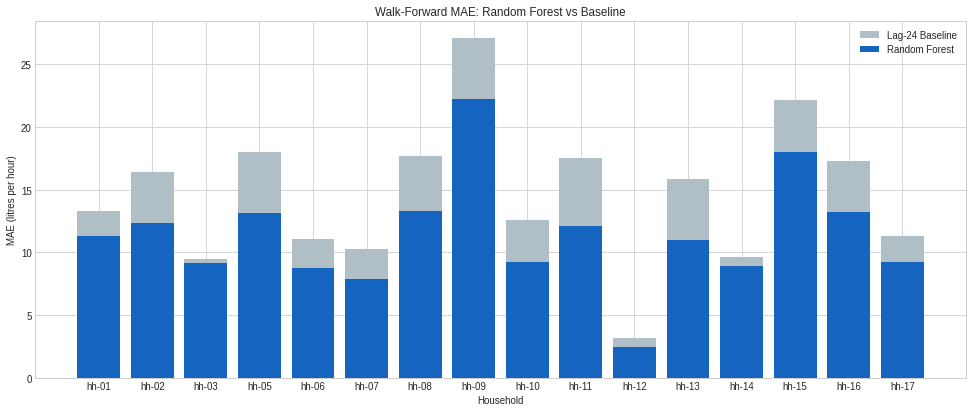

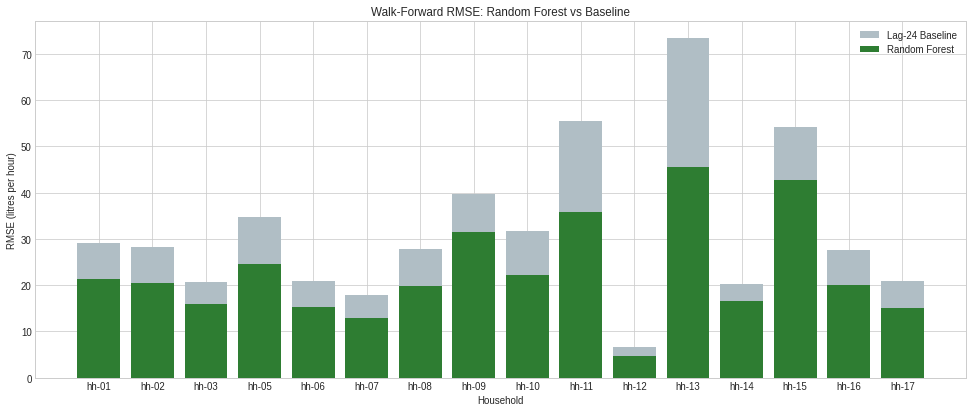

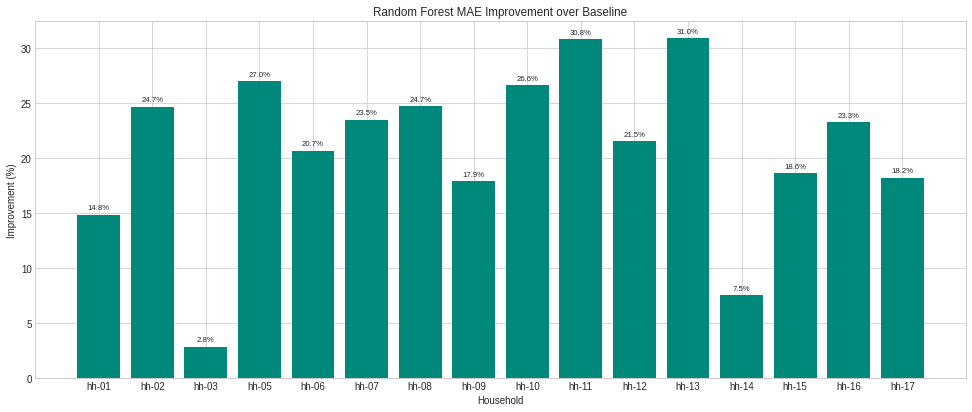

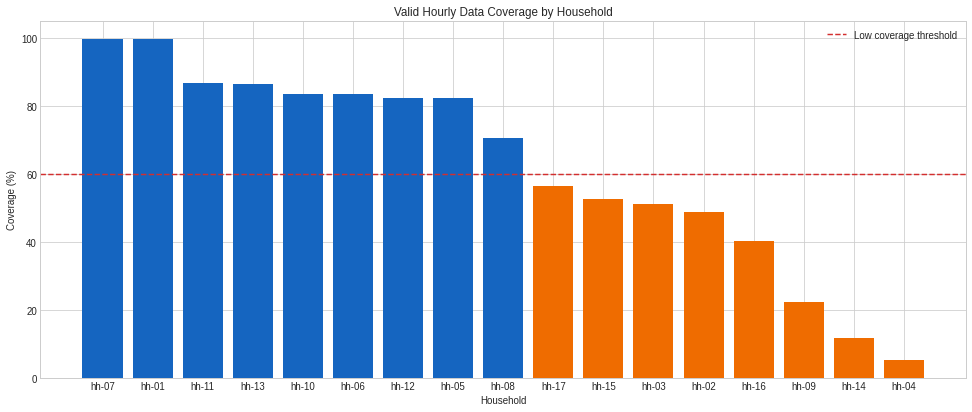

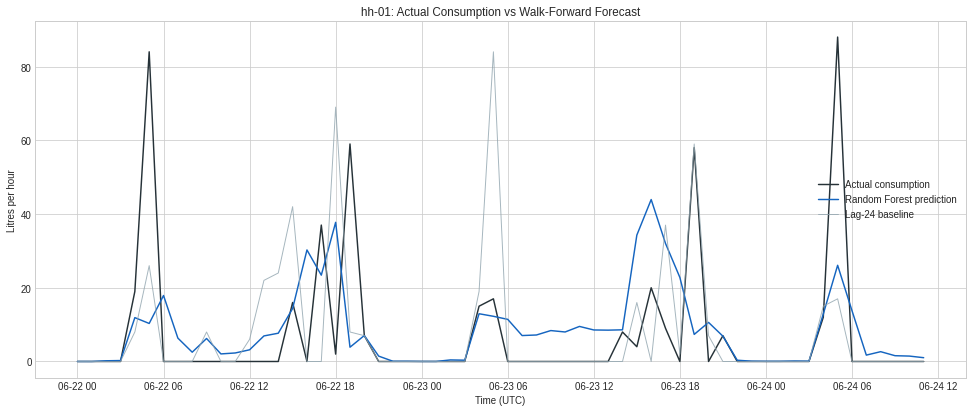

,household,coverage_percent,coverage_label,temporary_glitch_hours,rf_mae,rf_rmse,mae_improvement_percent,status
0,hh-01,99.56,Standard coverage,1,11.29,21.34,14.85,Completed
1,hh-02,48.76,Low coverage,4,12.37,20.54,24.70,Completed
2,hh-03,51.12,Low coverage,4,9.17,15.89,2.84,Completed
3,hh-04,5.25,Low coverage,4,NaN,NaN,NaN,Final model saved but no walk-forward test
4,hh-05,82.30,Standard coverage,6,13.15,24.60,27.00,Completed
5,hh-06,83.43,Standard coverage,11,8.78,15.37,20.68,Completed
6,hh-07,99.71,Standard coverage,1,7.85,12.87,23.52,Completed
7,hh-08,70.40,Standard coverage,11,13.29,19.83,24.73,Completed
8,hh-09,22.33,Low coverage,2,22.25,31.48,17.93,Completed
9,hh-10,83.56,Standard coverage,2,9.24,22.25,26.63,Completed


Saved table: /content/drive/MyDrive/watertwin/data/household_dashboard_summary.csv
Saved table: /content/drive/MyDrive/watertwin/data/model_comparison_table.csv
Saved graphs in: /content/drive/MyDrive/watertwin/graphs


In [48]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/watertwin/data")
GRAPH_DIR = Path("/content/drive/MyDrive/watertwin/graphs")
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

metrics = pd.read_csv(DATA_DIR / "walkforward_metrics_all.csv")
cleaning = pd.read_csv(DATA_DIR / "water_cleaning_summary.csv")
predictions = pd.read_csv(DATA_DIR / "walkforward_predictions_all.csv")

predictions["timestamp_utc"] = pd.to_datetime(
    predictions["timestamp_utc"],
    utc=True,
)

completed = metrics[metrics["status"].eq("Completed")].copy()

numeric_columns = [
    "baseline_mae",
    "baseline_rmse",
    "rf_mae",
    "rf_rmse",
    "mae_improvement_percent",
    "rmse_improvement_percent",
]

for column in numeric_columns:
    completed[column] = pd.to_numeric(
        completed[column],
        errors="coerce",
    )

completed = completed.sort_values("household")

dashboard_summary = cleaning.merge(
    metrics[
        [
            "household",
            "status",
            "final_training_rows",
            "walkforward_hours",
            "walkforward_weeks",
            "rf_mae",
            "rf_rmse",
            "mae_improvement_percent",
            "rmse_improvement_percent",
        ]
    ],
    on="household",
    how="left",
)

dashboard_summary["coverage_label"] = dashboard_summary[
    "coverage_percent"
].apply(
    lambda value: "Low coverage" if value < 60 else "Standard coverage"
)

dashboard_summary.to_csv(
    DATA_DIR / "household_dashboard_summary.csv",
    index=False,
)

completed.to_csv(
    DATA_DIR / "model_comparison_table.csv",
    index=False,
)

plt.style.use("seaborn-v0_8-whitegrid")

# Graph 1: MAE comparison
plt.figure(figsize=(14, 6))
plt.bar(
    completed["household"],
    completed["baseline_mae"],
    label="Lag-24 Baseline",
    color="#B0BEC5",
)
plt.bar(
    completed["household"],
    completed["rf_mae"],
    label="Random Forest",
    color="#1565C0",
)
plt.title("Walk-Forward MAE: Random Forest vs Baseline")
plt.xlabel("Household")
plt.ylabel("MAE (litres per hour)")
plt.legend()
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "09_all_households_mae_comparison.png",
    dpi=220,
)
plt.show()

# Graph 2: RMSE comparison
plt.figure(figsize=(14, 6))
plt.bar(
    completed["household"],
    completed["baseline_rmse"],
    label="Lag-24 Baseline",
    color="#B0BEC5",
)
plt.bar(
    completed["household"],
    completed["rf_rmse"],
    label="Random Forest",
    color="#2E7D32",
)
plt.title("Walk-Forward RMSE: Random Forest vs Baseline")
plt.xlabel("Household")
plt.ylabel("RMSE (litres per hour)")
plt.legend()
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "10_all_households_rmse_comparison.png",
    dpi=220,
)
plt.show()

# Graph 3: MAE improvement
plt.figure(figsize=(14, 6))
bars = plt.bar(
    completed["household"],
    completed["mae_improvement_percent"],
    color="#00897B",
)

plt.title("Random Forest MAE Improvement over Baseline")
plt.xlabel("Household")
plt.ylabel("Improvement (%)")

for bar, value in zip(
    bars,
    completed["mae_improvement_percent"],
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8,
    )

plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "11_all_households_mae_improvement.png",
    dpi=220,
)
plt.show()

# Graph 4: Data coverage
coverage_plot = dashboard_summary.sort_values(
    "coverage_percent",
    ascending=False,
)

bar_colors = coverage_plot["coverage_percent"].apply(
    lambda value: "#EF6C00" if value < 60 else "#1565C0"
)

plt.figure(figsize=(14, 6))
plt.bar(
    coverage_plot["household"],
    coverage_plot["coverage_percent"],
    color=bar_colors,
)

plt.axhline(
    60,
    color="#D32F2F",
    linestyle="--",
    label="Low coverage threshold",
)

plt.title("Valid Hourly Data Coverage by Household")
plt.xlabel("Household")
plt.ylabel("Coverage (%)")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "12_data_coverage_by_household.png",
    dpi=220,
)
plt.show()

# Graph 5: Example actual vs forecast for hh-01
example = predictions[
    predictions["household"].eq("hh-01")
].sort_values("timestamp_utc")

last_week_start = example["week_start_utc"].max()

example_week = example[
    example["week_start_utc"].eq(last_week_start)
]

plt.figure(figsize=(14, 6))
plt.plot(
    example_week["timestamp_utc"],
    example_week["actual_litres"],
    label="Actual consumption",
    color="#263238",
    linewidth=1.5,
)
plt.plot(
    example_week["timestamp_utc"],
    example_week["rf_prediction_litres"],
    label="Random Forest prediction",
    color="#1565C0",
    linewidth=1.5,
)
plt.plot(
    example_week["timestamp_utc"],
    example_week["baseline_lag24_litres"],
    label="Lag-24 baseline",
    color="#90A4AE",
    linewidth=1,
    alpha=0.8,
)

plt.title("hh-01: Actual Consumption vs Walk-Forward Forecast")
plt.xlabel("Time (UTC)")
plt.ylabel("Litres per hour")
plt.legend()
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "13_hh01_actual_vs_forecast.png",
    dpi=220,
)
plt.show()

display(
    dashboard_summary[
        [
            "household",
            "coverage_percent",
            "coverage_label",
            "temporary_glitch_hours",
            "rf_mae",
            "rf_rmse",
            "mae_improvement_percent",
            "status",
        ]
    ]
)

print("Saved table:", DATA_DIR / "household_dashboard_summary.csv")
print("Saved table:", DATA_DIR / "model_comparison_table.csv")
print("Saved graphs in:", GRAPH_DIR)

In [49]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/watertwin/data")

PREDICTIONS_FILE = DATA_DIR / "walkforward_predictions_all.csv"
ALERTS_FILE = DATA_DIR / "alerts_walkforward_all.csv"
THRESHOLDS_FILE = DATA_DIR / "anomaly_thresholds_all.csv"

LOCAL_TIMEZONE = "Europe/Berlin"

predictions = pd.read_csv(PREDICTIONS_FILE)

predictions["timestamp_utc"] = pd.to_datetime(
    predictions["timestamp_utc"],
    utc=True,
)

predictions["timestamp"] = predictions[
    "timestamp_utc"
].dt.tz_convert(LOCAL_TIMEZONE)

predictions["positive_error_litres"] = (
    predictions["actual_litres"]
    - predictions["rf_prediction_litres"]
).clip(lower=0)

thresholds = (
    predictions.groupby("household", as_index=False)
    .agg(
        prediction_hours=("actual_litres", "size"),
        unusual_usage_threshold_litres=(
            "positive_error_litres",
            lambda values: values.quantile(0.99),
        ),
    )
)

thresholds["unusual_usage_threshold_litres"] = thresholds[
    "unusual_usage_threshold_litres"
].round(2)

alerts = predictions.merge(
    thresholds[
        [
            "household",
            "unusual_usage_threshold_litres",
        ]
    ],
    on="household",
    how="left",
)

alerts = alerts[
    alerts["positive_error_litres"]
    > alerts["unusual_usage_threshold_litres"]
].copy()

alerts["alert_type"] = "Unusual usage"
alerts["severity"] = alerts.apply(
    lambda row: (
        "High"
        if row["positive_error_litres"]
        >= row["unusual_usage_threshold_litres"] * 1.5
        else "Moderate"
    ),
    axis=1,
)

alerts = alerts[
    [
        "timestamp",
        "timestamp_utc",
        "household",
        "alert_type",
        "severity",
        "actual_litres",
        "rf_prediction_litres",
        "positive_error_litres",
        "unusual_usage_threshold_litres",
    ]
].sort_values(
    ["severity", "positive_error_litres"],
    ascending=[True, False],
)

alerts.to_csv(ALERTS_FILE, index=False)
thresholds.to_csv(THRESHOLDS_FILE, index=False)

alert_summary = (
    alerts.groupby(
        ["household", "severity"],
        as_index=False,
    )
    .size()
    .rename(columns={"size": "alert_count"})
)

display(thresholds)
display(alert_summary)
display(alerts.head(30))

print("Saved:", ALERTS_FILE)
print("Saved:", THRESHOLDS_FILE)

,household,prediction_hours,unusual_usage_threshold_litres
0,hh-01,4066,94.85
1,hh-02,2580,82.33
2,hh-03,968,58.73
3,hh-05,8615,87.30
4,hh-06,3624,50.38
5,hh-07,3825,41.75
6,hh-08,8656,71.73
7,hh-09,311,101.15
8,hh-10,5322,73.60
9,hh-11,13638,84.59


,household,severity,alert_count
0,hh-01,High,10
1,hh-01,Moderate,31
2,hh-02,High,4
3,hh-02,Moderate,22
4,hh-03,High,2
5,hh-03,Moderate,8
6,hh-05,High,30
7,hh-05,Moderate,57
8,hh-06,High,17
9,hh-06,Moderate,19


,timestamp,timestamp_utc,household,alert_type,severity,actual_litres,rf_prediction_litres,positive_error_litres,unusual_usage_threshold_litres
42777,2021-06-13 17:00:00+02:00,2021-06-13 15:00:00+00:00,hh-11,Unusual usage,High,1099.0,43.910151,1055.089849,84.59
49343,2022-06-06 10:00:00+02:00,2022-06-06 08:00:00+00:00,hh-11,Unusual usage,High,1170.0,204.717020,965.282980,84.59
49344,2022-06-06 11:00:00+02:00,2022-06-06 09:00:00+00:00,hh-11,Unusual usage,High,1159.0,194.215613,964.784387,84.59
49341,2022-06-06 08:00:00+02:00,2022-06-06 06:00:00+00:00,hh-11,Unusual usage,High,1133.0,170.428667,962.571333,84.59
49347,2022-06-06 14:00:00+02:00,2022-06-06 12:00:00+00:00,hh-11,Unusual usage,High,1167.0,206.010675,960.989325,84.59
49349,2022-06-06 16:00:00+02:00,2022-06-06 14:00:00+00:00,hh-11,Unusual usage,High,1161.0,205.965413,955.034587,84.59
49342,2022-06-06 09:00:00+02:00,2022-06-06 07:00:00+00:00,hh-11,Unusual usage,High,1152.0,199.610786,952.389214,84.59
49348,2022-06-06 15:00:00+02:00,2022-06-06 13:00:00+00:00,hh-11,Unusual usage,High,1159.0,208.683334,950.316666,84.59
49346,2022-06-06 13:00:00+02:00,2022-06-06 11:00:00+00:00,hh-11,Unusual usage,High,1168.0,232.418952,935.581048,84.59
49345,2022-06-06 12:00:00+02:00,2022-06-06 10:00:00+00:00,hh-11,Unusual usage,High,1153.0,224.859880,928.140120,84.59


Saved: /content/drive/MyDrive/watertwin/data/alerts_walkforward_all.csv
Saved: /content/drive/MyDrive/watertwin/data/anomaly_thresholds_all.csv
